# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [37]:
team_setup = {
    'team_name': 'DannyTuran',
    'members': [                                  # everyone on the team, 2 to 4 people
        {'name': 'Danny Oppenheimer', 'github': 'https://github.com/DannyOppenheimer'},
        {'name': 'TODO', 'github': 'https://github.com/TuranAhmad04'},
    ],
    'repo_url': 'https://github.com/DannyOppenheimer/walmart-hurricane-project',
    'charter_url': 'https://github.com/DannyOppenheimer/walmart-hurricane-project/blob/main/CHARTER.md',
    'notebook_owner_this_week': 'Danny Oppenheimer',
    'meeting_time': 'We live together, no set meeting time',
    'five_worst_problems': ['TODO'],              # nice to have, five specific problems
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  FAIL - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  not yet - five specific problems

team setup complete: False


False

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [38]:
import subprocess

REPO_PATH = '../'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

9325bf4 Fix team charter
e8c5a27 Initial commit


In [39]:
import pandas as pd

df = pd.read_csv('../data/walmart_transactions.csv', dtype=str)


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [40]:
decision_log = []

def clean_store_id(df):

    out = df.copy()
    cleaned = (out['store_id']
               .str.strip()
               .str.upper()
               .str.replace(r'^([A-Z]{2})[-_ ]?(\d+)$', r'\1-\2', regex=True))

    decision_log.append({
        'step': 'clean_store_id',
        'decision': "trimmed spaces, uppercased, unified separator to 'XX-###'",
        'rows_touched': int((cleaned != out['store_id']).sum()),
        'rows_dropped': 0,
    })

    out['store_id'] = cleaned
    return out

def drop_duplicates(df):

    out = df.drop_duplicates(keep='first')

    decision_log.append({
        'step': 'drop_duplicates',
        'decision': 'removed exact duplicate rows, kept the first copy',
        'rows_touched': len(df) - len(out),
        'rows_dropped': len(df) - len(out),
    })

    return out

def drop_near_duplicates(df):

    # Same row in every column except transaction_id. Rows with no timestamp are
    # left alone: with the time unknown we cannot say two rows are the same purchase.
    match_cols = [c for c in df.columns if c != 'transaction_id']
    is_copy = df.sort_values('transaction_id').duplicated(subset=match_cols, keep='first')
    is_copy &= df.loc[is_copy.index, 'timestamp'].notna()

    dropped = df.loc[is_copy[is_copy].index, 'transaction_id']
    out = df.drop(index=dropped.index)

    decision_log.append({
        'step': 'drop_near_duplicates',
        'decision': f'dropped rows identical to another row in every column except transaction_id, '
                    f'keeping the lowest ID. The dropped copies have IDs {dropped.min()} to {dropped.max()} '
                    f'(one consecutive block) and differ from the original only by ID, which points to '
                    f're-entered copies. RISK: two shoppers could genuinely have made the same purchase '
                    f'at the same store and second, in which case we undercount by {len(dropped)} rows '
                    f'({len(dropped) / len(df):.2%} of rows). We judge that unlikely and the cleanup defensible.',
        'rows_touched': len(dropped),
        'rows_dropped': len(dropped),
    })

    return out

# The five formats in the raw data
TIMESTAMP_FORMATS = [
    '%Y-%m-%dT%H:%M:%S',
    '%Y-%m-%d %H:%M:%S', 
    '%m/%d/%Y %H:%M',
    '%m-%d-%Y %H:%M:%S',
    '%d-%b-%Y %H:%M',
]

def parse_timestamp(df):

    out = df.copy()
    parsed = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')

    for fmt in TIMESTAMP_FORMATS:
        parsed = parsed.fillna(pd.to_datetime(out['timestamp'], format=fmt, errors='coerce'))

    blank = int(out['timestamp'].isna().sum())
    unparseable = int(parsed.isna().sum()) - blank

    decision_log.append({
        'step': 'parse_timestamp',
        'decision': f'parsed 5 formats to datetime (month-first) - {blank} blank timestamps - {unparseable} unparseable',
        'rows_touched': int(parsed.notna().sum()),
        'rows_dropped': 0,
    })

    out['timestamp'] = parsed
    return out

def clean_price(df):

    out = df.copy()
    has_dollar = out['unit_price'].str.contains('$', regex=False)
    numeric = pd.to_numeric(out['unit_price'].str.replace('$', '', regex=False).str.strip(), errors='coerce')

    unparseable = int(numeric.isna().sum() - out['unit_price'].isna().sum())

    decision_log.append({
        'step': 'clean_price',
        'decision': f"stripped '$' and converted unit_price to float - {unparseable} unparseable",
        'rows_touched': int(has_dollar.sum()),
        'rows_dropped': 0,
    })

    out['unit_price'] = numeric
    return out

CATEGORY_MAP = {
    'alcohol': 'Alcohol',           'alcoholic beverages': 'Alcohol',
    'baby': 'Baby',                 'baby products': 'Baby',
    'breakfast': 'Breakfast',       'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency',       'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery',           'groceries': 'Grocery',
    'health': 'Health',             'health & wellness': 'Health',
    'household': 'Household',       'household essentials': 'Household',
    'snacks': 'Snacks',
}

def clean_category(df):

    out = df.copy()
    key = out['category'].str.strip().str.lower()
    mapped = key.map(CATEGORY_MAP)

    # A spelling we have not seen is kept as-is
    unmapped = int(mapped.isna().sum() - out['category'].isna().sum())
    mapped = mapped.fillna(out['category'].str.strip())

    decision_log.append({
        'step': 'clean_category',
        'decision': f"merged {out['category'].nunique()} category spellings into {mapped.nunique()} "
                    f"canonical categories - {unmapped} rows with an unmapped spelling",
        'rows_touched': int((mapped != out['category']).sum()),
        'rows_dropped': 0,
    })

    out['category'] = mapped
    return out

def handle_negative_quantity(df):

    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')

    negative = out['quantity'] < 0
    out = out[~negative]

    decision_log.append({
        'step': 'handle_negative_quantity',
        'decision': 'dropped rows with quantity < 0 - (if we are trying to analyze purchase behavior, returns are too small to help make decisions, so we can safely drop them)',
        'rows_touched': int(negative.sum()),
        'rows_dropped': int(negative.sum()),
    })

    return out

begin_rows = len(df)

tx = clean_store_id(df)
tx = parse_timestamp(tx)
tx = clean_price(tx)
tx = clean_category(tx)
tx = drop_duplicates(tx)
tx = drop_near_duplicates(tx)
tx = handle_negative_quantity(tx)

end_rows = len(tx)
print(f"Started with {begin_rows} rows, now has {end_rows} (diff of {begin_rows - end_rows})")

Started with 25562 rows, now has 25372 (diff of 190)


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [41]:
pd.set_option('display.max_colwidth', None)

log = pd.DataFrame(decision_log)
log.index = log.index + 1
log.index.name = '#'

display(log)
print('total rows touched:', log['rows_touched'].sum())
print('total rows dropped:', log['rows_dropped'].sum())
print('matches before/after row counts:', log['rows_dropped'].sum() == begin_rows - end_rows)

,step,decision,rows_touched,rows_dropped
#,,,,
1,clean_store_id,"trimmed spaces, uppercased, unified separator to 'XX-###'",4348,0
2,parse_timestamp,parsed 5 formats to datetime (month-first) - 886 blank timestamps - 0 unparseable,24676,0
3,clean_price,stripped '$' and converted unit_price to float - 0 unparseable,3029,0
4,clean_category,merged 37 category spellings into 10 canonical categories - 0 rows with an unmapped spelling,18760,0
5,drop_duplicates,"removed exact duplicate rows, kept the first copy",30,30
6,drop_near_duplicates,"dropped rows identical to another row in every column except transaction_id, keeping the lowest ID. The dropped copies have IDs TXN025503 to TXN025532 (one consecutive block) and differ from the original only by ID, which points to re-entered copies. RISK: two shoppers could genuinely have made the same purchase at the same store and second, in which case we undercount by 30 rows (0.12% of rows). We judge that unlikely and the cleanup defensible.",30,30
7,handle_negative_quantity,"dropped rows with quantity < 0 - (if we are trying to analyze purchase behavior, returns are too small to help make decisions, so we can safely drop them)",130,130


total rows touched: 51003
total rows dropped: 190
matches before/after row counts: True


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [42]:

SKU_MAP = {
    # Breakfast
    'PT-12':         'Pop-Tarts Strawberry',
    'SKU#459812':    'Pop-Tarts Strawberry',
    'POPTART-STRAW': 'Pop-Tarts Strawberry',
    'PT_STRAWBERRY': 'Pop-Tarts Strawberry',
    # Emergency
    'WTR-24':        'Bottled Water 24-Pack',
    'WATER24PK':     'Bottled Water 24-Pack',
    'WTR_24PK':      'Bottled Water 24-Pack',
    'BATT-100':      'AA Batteries 4-Pack',
    'BAT-AA4':       'AA Batteries 4-Pack',
    'BATT_AA_4PK':   'AA Batteries 4-Pack',
    'FLASH-01':      'LED Flashlight',
    'LED-FLASH':     'LED Flashlight',
    'CNDL-EM':       'Emergency Candles',
    'CANDLE-EMRG':   'Emergency Candles',
    'TARP-HD':       'Heavy Duty Tarp',
    'HDTARP-01':     'Heavy Duty Tarp',
    # Alcohol
    'BEER-24':       'Light Beer 24-Pack',
    'LTBEER24':      'Light Beer 24-Pack',
    # Entertainment
    'BG-MONO':       'Monopoly Board Game',
    'MONOPOLY-01':   'Monopoly Board Game',
    'GAME-MONO':     'Monopoly Board Game',
    'CARDS-01':      'Playing Cards',
    'PLAYCARD-STD':  'Playing Cards',
    # Electronics
    'STREAM-01':     'Roku Streaming Stick',
    'ROKU-STD':      'Roku Streaming Stick',
    'CHRG-PORT':     'Portable Phone Charger',
    'PORTCHARGER':   'Portable Phone Charger',
    # Grocery
    'SOUP-CAN':      'Canned Soup',
    'CNSOUP-01':     'Canned Soup',
    'BREAD-WH':      'White Bread',
    'WHITEBREAD':    'White Bread',
    'PB-16':         'Peanut Butter 16oz',
    'PNUTBTR-16':    'Peanut Butter 16oz',
    # Snacks
    'CHIPS-VP':      'Chips Variety Pack',
    'CHIPVARIETY':   'Chips Variety Pack',
    # Health
    'FAID-01':       'First Aid Kit',
    'FIRSTAID-KIT':  'First Aid Kit',
    # Household
    'PTOWEL-6':      'Paper Towels 6-Roll',
    'PAPERTOWEL6':   'Paper Towels 6-Roll',
    'TP-12':         'Toilet Paper 12-Roll',
    'TOILETPAPER12': 'Toilet Paper 12-Roll',
    # Baby
    'DIAP-S3':       'Diapers Size 3',
    'DIAPERS-3':     'Diapers Size 3',
    'BFORM-01':      'Baby Formula',
    'BABYFORMULA':   'Baby Formula',
}

def consolidate_sku(df):

    out = df.copy()
    out['product'] = out['sku'].str.strip().map(SKU_MAP)
    unmapped = int(out['product'].isna().sum())

    decision_log.append({
        'step': 'consolidate_sku',
        'decision': f"mapped {out['sku'].nunique()} SKUs to {out['product'].nunique()} canonical "
                    f"products with a hand-built SKU_MAP (checked against product_catalog.csv) - "
                    f"{unmapped} unmapped rows. Package sizes in the catalog disagree within a "
                    f"product (e.g. Pop-Tarts 4-pack vs 6 pack) and transactions do not record "
                    f"size, so SKUs of the same product are merged regardless of listed size.",
        'rows_touched': len(out) - unmapped,
        'rows_dropped': 0,
    })

    return out

catalog = pd.read_csv('../data/product_catalog.csv', dtype=str)

# Check every SKU in the data and the catalog is mapped
assert set(tx['sku'].str.strip()) <= SKU_MAP.keys(), set(tx['sku']) - SKU_MAP.keys()
assert set(catalog['sku']) == SKU_MAP.keys()

tx = consolidate_sku(tx)
assert tx['product'].notna().all()

# Check no spelling of product_name lands in two different products
names_per_product = tx.assign(name=tx['product_name'].str.strip()).groupby('name')['product'].nunique()
assert (names_per_product == 1).all(), names_per_product[names_per_product > 1]

groups = tx.groupby('product')['sku'].nunique().sort_values(ascending=False)
print('Distinct SKUs before:', df['sku'].nunique())
print('Canonical products after:', tx['product'].nunique())
print(f'Largest consolidated group: {groups.index[0]} ({groups.iloc[0]} SKUs)')
print()

# Show info of pop tarts
poptarts = tx[tx['product'] == 'Pop-Tarts Strawberry']
display(poptarts.groupby('sku').agg(
    spellings=('product_name', lambda s: sorted(s.str.strip().unique())),
    rows=('sku', 'size'),
    units=('quantity', 'sum'),
))

# Show info on all changess
display(tx.groupby('product').agg(skus=('sku', 'nunique'), rows=('sku', 'size'), units=('quantity', 'sum'))
          .sort_values(['skus', 'units'], ascending=False))


Distinct SKUs before: 45
Canonical products after: 20
Largest consolidated group: Pop-Tarts Strawberry (4 SKUs)



,spellings,rows,units
sku,,,
POPTART-STRAW,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, Pop-Tarts Strawberry, Strawberry Pop-Tart, pop-tarts strawberry]",502,1298
PT-12,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, Pop-Tarts Strawberry, Strawberry Pop-Tart, pop-tarts strawberry]",536,1381
PT_STRAWBERRY,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, Pop-Tarts Strawberry, Strawberry Pop-Tart, pop-tarts strawberry]",512,1262
SKU#459812,"[POPTART-STRAWBERRY, Pop Tarts - Strawberry, Pop-Tarts Strawberry, Strawberry Pop-Tart, pop-tarts strawberry]",502,1255


,skus,rows,units
product,,,
Pop-Tarts Strawberry,4,2052,5196
Bottled Water 24-Pack,3,1485,5224
AA Batteries 4-Pack,3,1451,4296
Monopoly Board Game,3,1332,2015
LED Flashlight,2,1451,2907
Canned Soup,2,1045,2637
Emergency Candles,2,1301,2612
Light Beer 24-Pack,2,1256,2577
Playing Cards,2,1193,2378


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [43]:
import requests, time
import numpy as np

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def daily_weather(start, end, lat=28.54, lon=-81.38, tries=3):

    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max',
        'timezone': 'America/New_York',
    }
    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError) as err:
            print(f'attempt {attempt}: {type(err).__name__}')
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            print(f'attempt {attempt}: HTTP {r.status_code}, retrying')
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()                      # any other bad status fails loudly
        body = r.json()
        frame = pd.DataFrame(body['daily']).rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])     # string -> datetime right away
        frame['source'] = 'open-meteo'
        frame.attrs['timezone'] = body.get('timezone')
        return frame

# Saved copy
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'source': 'fallback sample',
})

start, end = tx['timestamp'].min().date(), tx['timestamp'].max().date()
try:
    weather = daily_weather(str(start), str(end))
except requests.RequestException as err:
    print('API call failed:', err)
    weather = FALLBACK

print('source:', weather['source'].iloc[0], '| timezone:', weather.attrs.get('timezone', 'America/New_York'))
print('weather rows:', len(weather), f'({weather["date"].min():%b %d} to {weather["date"].max():%b %d})')
display(weather)

# Line weather up with sales
daily_orders = (tx.dropna(subset=['timestamp'])
                  .assign(date=lambda d: d['timestamp'].dt.normalize())
                  .groupby('date').size().rename('orders').reset_index())

merged = daily_orders.merge(weather, on='date', how='left', indicator=True)
assert len(merged) == len(daily_orders), 'the join changed the row count'
assert merged['orders'].sum() == daily_orders['orders'].sum(), 'the orders total changed'
missing = merged.loc[merged['_merge'] == 'left_only', 'date']
print('sales days:', len(daily_orders), '| matched to weather:', (merged['_merge'] == 'both').sum(),
      '| sales days with no weather:', missing.dt.date.tolist())
print('rows with no timestamp, so no day to join on:', int(tx['timestamp'].isna().sum()))
display(merged.drop(columns='_merge').head())


source: open-meteo | timezone: America/New_York
weather rows: 30 (Sep 01 to Sep 30)


,date,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,3.0,18.8,open-meteo
1,2024-09-02,12.4,13.5,open-meteo
2,2024-09-03,24.9,22.8,open-meteo
3,2024-09-04,22.1,15.5,open-meteo
4,2024-09-05,23.1,15.2,open-meteo
5,2024-09-06,9.3,9.0,open-meteo
6,2024-09-07,6.8,14.2,open-meteo
7,2024-09-08,94.7,12.6,open-meteo
8,2024-09-09,28.0,11.5,open-meteo
9,2024-09-10,14.4,14.3,open-meteo


sales days: 30 | matched to weather: 30 | sales days with no weather: []
rows with no timestamp, so no day to join on: 881


,date,orders,precipitation_sum,windspeed_10m_max,source
0,2024-09-01,582,3.0,18.8,open-meteo
1,2024-09-02,576,12.4,13.5,open-meteo
2,2024-09-03,583,24.9,22.8,open-meteo
3,2024-09-04,559,22.1,15.5,open-meteo
4,2024-09-05,804,23.1,15.2,open-meteo


**Timezone and alignment.**

- **Weather:** the request passes `timezone='America/New_York'`, so Open-Meteo cuts each daily total and max at local midnight (EDT, UTC-4, in September). Without that parameter the days would be cut in UTC, and every "day" of rain would run 8pm to 8pm local.
- **Sales:** `timestamp` has no timezone marker. We treat it as store-local time, because every transaction falls between 06:00 and 22:59, which matches store hours. If it were UTC, stores would be open 2am to 7pm, which is not plausible.
- **Lining them up:** each sales timestamp is cut back to its calendar day with `.dt.normalize()`, then weather is **left**-joined on `date` (both sides `datetime64`), so no sales day can drop out. Checks: the row count and the orders total are unchanged, and every sales day matched (30 of 30).
- **Caveats:**
  - The 881 rows with no timestamp cannot be placed on a day, so they are not in the daily join.
  - One Orlando call stands in for all stores. Pensacola (FL-710) is on Central time and about 400 miles away, so for Q4 we will call `daily_weather` per store using each store's coordinates. Tallahassee (FL-619) has no coordinates yet.
  - The live archive differs slightly from the course's saved copy. Rain matches, but max wind differs on 3 days, e.g. Sept 27 is 40.1 km/h live vs 45.1 saved. The archive data gets revised, so we keep the `source` column all the way through.

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

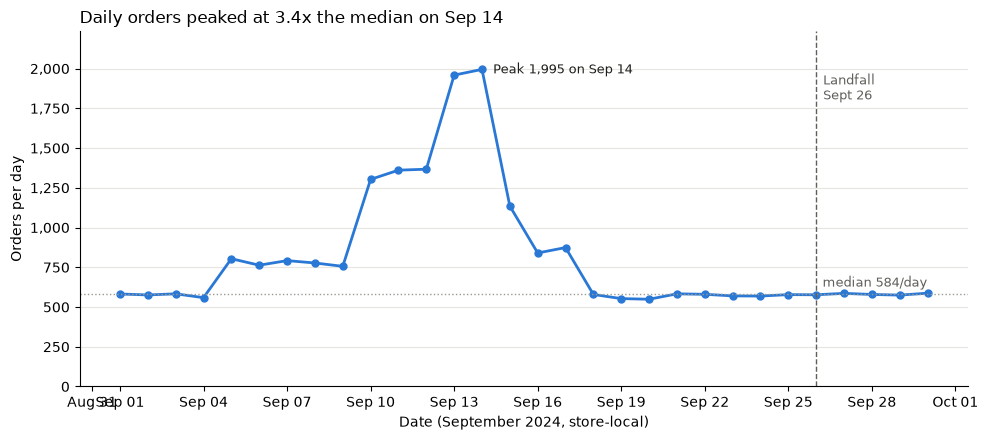

days plotted: 30 (Sep 01 to Sep 30)
zero-order days: []
days above 10x median: []
peak is 12 day(s) before landfall


In [44]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

LANDFALL = pd.Timestamp('2024-09-26')    # Helene's Big Bend landfall

# daily_orders comes from section 4: one row per day, cleaned transactions only
daily = daily_orders.set_index('date')['orders']
all_days = pd.date_range(daily.index.min(), daily.index.max())
daily = daily.reindex(all_days, fill_value=0)

peak_day, peak = daily.idxmax(), daily.max()
typical = daily.median()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(daily.index, daily.values, color='#2a78d6', lw=2, marker='o', ms=5)

ax.axhline(typical, color='#9a9a94', ls=':', lw=1)
ax.annotate(f'median {typical:,.0f}/day', (daily.index[-1], typical), xytext=(0, 5),
            textcoords='offset points', ha='right', fontsize=9, color='#5f5f5a')
ax.axvline(LANDFALL, color='#5f5f5a', ls='--', lw=1)
ax.annotate('Landfall\nSept 26', (LANDFALL, peak), xytext=(5, -2),
            textcoords='offset points', va='top', fontsize=9, color='#5f5f5a')
ax.annotate(f'Peak {peak:,} on {peak_day:%b %d}', (peak_day, peak), xytext=(8, 0), textcoords='offset points',
            va='center', fontsize=9, color='#1f1f1c')

ax.set_title(f'Daily orders peaked at {peak / typical:.1f}x the median on {peak_day:%b %d}',
             loc='left', fontsize=12)
ax.set_xlabel('Date (September 2024, store-local)')
ax.set_ylabel('Orders per day')
ax.set_ylim(0, peak * 1.12)
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=range(1, 32, 3)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.grid(axis='y', color='#e6e5e0', lw=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

print('days plotted:', len(daily), f'({daily.index.min():%b %d} to {daily.index.max():%b %d})')
print('zero-order days:', daily.index[daily == 0].strftime('%b %d').tolist())
print('days above 10x median:', daily.index[daily > 10 * typical].strftime('%b %d').tolist())
lead = (LANDFALL - peak_day).days
print(f'peak is {lead} day(s) before landfall' if lead >= 0 else f'peak is {-lead} day(s) AFTER landfall')
if not 0 <= lead <= 3:
    print('WARNING: the peak is not in the days just before landfall. Check that the data '
          'files are the post-Wednesday copy with dates moved to line up with Helene.')


### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [45]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),   # from the team setup section
    'charter_committed': False,         # TODO: True once CHARTER.md shows in the git log above
}

progress = {
    'rows_after_cleaning': None,        # an integer
    'decisions_logged': None,           # how many entries in your log
    'canonical_products': None,         # distinct products after consolidation
    'weather_api_rows': None,           # rows returned by your API call
    'notebook_runs_clean': False,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  FAIL - team_setup_complete = False
  FAIL - charter_committed = False
PROGRESS (fill in what you have)
  not yet - rows_after_cleaning = None
  not yet - decisions_logged = None
  not yet - canonical_products = None
  not yet - weather_api_rows = None
  not yet - notebook_runs_clean = False

required items complete: False
progress items done: 0 of 5


False

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** _..._

**Plan, with an owner and a date:** _..._

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | not started / in progress / draft answer | _..._ |
| Q2 SKU consolidation | _..._ | _..._ |
| Q3 weather correlation | _..._ | _..._ |
| Q4 store and geography | _..._ | _..._ |
| Q5 signal or artifact | _..._ | _..._ |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.